# 06 · Final results and slide figures
**Study Smarter, Not Harder** (working title) · Member D (Auditor + designer) · whole team

This notebook does **no new modelling**. It assembles what notebooks 01-05 saved in `results/*.csv` (plus simple
descriptive statistics of the cleaned data and two numbers read from the executed output of notebook 03), and
produces the slide figures in `presentation/` and the one-page `presentation/executive_summary.md`.

**Model numbering (used everywhere in this project, defined in notebook 03):**

| Model | Formula (all OLS, HC3 robust SEs) |
|---|---|
| **M1** | G3 ~ study time |
| **M2** | M1 + academic/demographic: failures, log(absences+1), sex, age, school, address, wants higher education |
| **M3** | M2 + family/social/support: Medu, Fedu, goout, Dalc, Walc, freetime, health, internet, schoolsup, famsup, paid, romantic (**the main controls model**) |
| **M4** | M3 + G1 + G2 (earlier grades) |

**Samples:** *all* = 649 students of the Portuguese course; *G3 > 0* = 634, i.e. without the 15 **zero-grade cases**
(G3 = 0). In the narrative we call them **apparent dropouts**; that is our interpretation, since the dataset does
not record why a final grade is 0 (see notebook 04).

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

PROC, RES, FIG, PRES, NBS = (Path("../data/processed"), Path("../results"), Path("../figures"),
                             Path("../presentation"), Path("."))
PRES.mkdir(exist_ok=True)
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#9a9a94", "#1f1f1d", "#6b6b66"
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
                     "font.size": 16, "axes.titlesize": 20, "axes.labelsize": 16, "xtick.labelsize": 15,
                     "ytick.labelsize": 15, "legend.fontsize": 14, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#bdbdb8", "axes.grid": True,
                     "grid.color": "#e6e6e3", "text.color": INK, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "savefig.dpi": 200})
pd.set_option("display.width", 180); pd.set_option("display.max_colwidth", 80)
ST_LABELS = {1: "<2 h", 2: "2-5 h", 3: "5-10 h", 4: ">10 h"}

ht = pd.read_csv(RES / "hypothesis_tests.csv")
rc = pd.read_csv(RES / "regression_comparison.csv")
sc = pd.read_csv(RES / "diagnostics_scorecard.csv")
ba = pd.read_csv(RES / "zero_grade_before_after.csv").set_index("sample")
rb = pd.read_csv(RES / "zero_grade_robustness.csv").set_index("treatment")
df = pd.read_csv(PROC / "student-por_clean.csv")
mat = pd.read_csv(PROC / "student-mat_clean.csv")
nz = df[~df.zero_grade]
SAMPLES = {"all": df, "G3>0": nz}


def H(test, sample="all", col="p_value"):
    """One value from results/hypothesis_tests.csv."""
    r = ht[(ht.test == test) & (ht["sample"] == sample)]
    assert len(r) == 1, (test, sample, len(r))
    return r.iloc[0][col]


def R(section, model, sample, term, col="estimate"):
    """One value from results/regression_comparison.csv."""
    r = rc[(rc.section == section) & (rc.model.str.startswith(model)) & (rc["sample"] == sample) & (rc.term == term)]
    assert len(r) == 1, (section, model, sample, term, len(r))
    return r.iloc[0][col]


def S(check, sample, col="statistic"):
    r = sc[(sc.check == check) & (sc["sample"] == sample)]
    assert len(r) == 1, (check, sample)
    return r.iloc[0][col]


def nb_output(nb_file, marker):
    """Concatenated text output of the code cell in an executed notebook whose source contains `marker`."""
    nb = json.loads((NBS / nb_file).read_text())
    hits = [c for c in nb["cells"] if c["cell_type"] == "code" and marker in "".join(c["source"])]
    assert len(hits) == 1, (nb_file, marker, len(hits))
    out = []
    for o in hits[0].get("outputs", []):
        t = o.get("text") or o.get("data", {}).get("text/plain") or ""
        out.append("".join(t))
    return "\n".join(out)


def ci(lo, hi, f="{:+.2f}"):
    return f"[{f.format(lo)}, {f.format(hi)}]"


def pfmt(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

print(df.shape, nz.shape, mat.shape, "| zero-grade cases:", int(df.zero_grade.sum()))

(649, 35) (634, 35) (395, 35) | zero-grade cases: 15


## 1. Descriptive statistics

In [2]:
VARS = {"G3": "final grade G3 (0-20)", "G1": "period-1 grade G1", "G2": "period-2 grade G2",
        "studytime": "study time (1-4 scale)", "failures": "past class failures", "absences": "absences (count)",
        "age": "age (years)"}
rows = []
for v, lab in VARS.items():
    for s, d in SAMPLES.items():
        x = d[v]
        rows.append({"variable": lab, "sample": s, "n": len(x), "mean": x.mean(), "sd": x.std(),
                     "median": x.median(), "min": x.min(), "max": x.max()})
desc = pd.DataFrame(rows).set_index(["variable", "sample"])
display(desc.round(2))

shares = pd.DataFrame({s: {"female": (d.sex == "F").mean(), "school MS": (d.school == "MS").mean(),
                           "wants higher education": (d.higher == "yes").mean(),
                           "family support": (d.famsup == "yes").mean(),
                           "extra school support": (d.schoolsup == "yes").mean(),
                           "zero absences": (d.absences == 0).mean()} for s, d in SAMPLES.items()})
display((100 * shares).round(1).rename(columns=lambda c: f"% ({c})"))

n   mean    sd  median  min  max
variable               sample                                    
final grade G3 (0-20)  all     649  11.91  3.23    12.0    0   19
                       G3>0    634  12.19  2.69    12.0    1   19
period-1 grade G1      all     649  11.40  2.75    11.0    0   19
                       G3>0    634  11.50  2.68    11.0    0   19
period-2 grade G2      all     649  11.57  2.91    11.0    0   19
                       G3>0    634  11.75  2.63    12.0    5   19
study time (1-4 scale) all     649   1.93  0.83     2.0    1    4
                       G3>0    634   1.94  0.83     2.0    1    4
past class failures    all     649   0.22  0.59     0.0    0    3
                       G3>0    634   0.21  0.58     0.0    0    3
absences (count)       all     649   3.66  4.64     2.0    0   32
                       G3>0    634   3.75  4.66     2.0    0   32
age (years)            all     649  16.74  1.22    17.0   15   22
                       G3>0    634  16.72  1.21    17.0   15   22

,% (all),% (G3>0)
female,59.0,59.3
school MS,34.8,33.4
wants higher education,89.4,89.9
family support,61.3,62.1
extra school support,10.5,10.6
zero absences,37.6,36.1


In [3]:
# G3 by study-time group (descriptive; t-based 95% CI of each group mean)
rows = []
for s, d in SAMPLES.items():
    for k, g in d.groupby("studytime").G3:
        h = stats.t.ppf(0.975, len(g) - 1) * g.std() / np.sqrt(len(g))
        rows.append({"sample": s, "study time": ST_LABELS[k], "n": len(g), "mean G3": g.mean(), "sd": g.std(),
                     "ci_lo": g.mean() - h, "ci_hi": g.mean() + h})
grp = pd.DataFrame(rows)
display(grp.round(2).set_index(["sample", "study time"]))

n  mean G3    sd  ci_lo  ci_hi
sample study time                                  
all    <2 h        212    10.84  3.22  10.41  11.28
       2-5 h       305    12.09  3.24  11.73  12.46
       5-10 h       97    13.23  2.50  12.72  13.73
       >10 h        35    13.06  3.04  12.01  14.10
G3>0   <2 h        204    11.27  2.44  10.93  11.61
       2-5 h       298    12.38  2.69  12.07  12.68
       5-10 h       97    13.23  2.50  12.72  13.73
       >10 h        35    13.06  3.04  12.01  14.10

**Reading:** mean G3 is 11.9 on all students; the 15 zero-grade cases pull the minimum to 0 and the next-lowest
grade is 1. Mean G3 rises from the <2 h group to 5-10 h and then flattens at >10 h (n = 35).

## 2. Hypothesis tests (notebook 02)

In [4]:
KEEP = [
    ("One-way ANOVA G3 ~ studytime", "RQ1"), ("Levene equal variances (G3 by studytime)", "RQ1"),
    ("Kruskal-Wallis G3 ~ studytime", "RQ1"), ("Tukey HSD <2 h vs 5-10 h", "RQ1"), ("Tukey HSD 5-10 h vs >10 h", "RQ1"),
    ("ANCOVA G3 ~ C(studytime) + G1: studytime", "RQ3"), ("MANOVA (G1,G2,G3) ~ studytime", "RQ3"),
    ("MANCOVA (+failures) (G1,G2,G3) ~ studytime", "RQ3"),
    ("Welch t G3 by higher (yes - no)", "groups"), ("Welch t G3 by famsup (yes - no)", "groups"),
    ("Welch t G3 by schoolsup (yes - no)", "groups"), ("Welch t G3 by sex (F - M)", "groups"),
    ("Pearson r(absences, G3)", "RQ4"), ("Spearman rho(absences, G3)", "RQ4"),
    ("Two-way ANOVA (studytime x sex): C(studytime):C(sex)", "backup"),
    ("Fisher exact zero-grade x school", "RQ5"),
]
rows = []
for t, rq in KEEP:
    for s in ["all", "G3>0"]:
        r = ht[(ht.test == t) & (ht["sample"] == s)]
        if r.empty:
            continue
        r = r.iloc[0]
        eff = f"{r.effect_size} = {r.effect:.3f}" if pd.notna(r.effect) else ""
        if pd.notna(r.effect_ci_lo):
            eff += f" [{r.effect_ci_lo:.2f}, {r.effect_ci_hi:.2f}]"
        df_ = f"({r.df})" if pd.notna(r.df) else ""
        rows.append({"RQ": rq, "test": t, "sample": s, "n": int(r.n),
                     "statistic": f"{r.statistic}{df_} = {r.value:.3f}", "p": pfmt(r.p_value),
                     "effect [95% CI]": eff, "reject H0 at 5%": "yes" if r.p_value < 0.05 else "no"})
tests = pd.DataFrame(rows).set_index(["RQ", "test", "sample"])
tests

n                  statistic        p                                effect [95% CI] reject H0 at 5%
RQ     test                                                 sample                                                                                                        
RQ1    One-way ANOVA G3 ~ studytime                         all     649         F(3, 645) = 15.876  < 0.001                     eta^2 = 0.069 [0.04, 0.11]             yes
                                                            G3>0    634         F(3, 630) = 15.417  < 0.001                     eta^2 = 0.068 [0.04, 0.11]             yes
       Levene equal variances (G3 by studytime)             all     649          W(3, 645) = 1.026    0.380                                                             no
                                                            G3>0    634          W(3, 630) = 2.235    0.083                                                             no
       Kruskal-Wallis G3 ~ studytime                        all     649              H(3) = 50.316  < 0.001                              epsilon^2 = 0.078             yes
                                                            G3>0    634              H(3) = 45.576  < 0.001                              epsilon^2 = 0.072             yes
       Tukey HSD <2 h vs 5-10 h                             all     649          mean diff = 2.382  < 0.001     mean diff (G3 points) = 2.382 [1.40, 3.37]             yes
                                                            G3>0    634          mean diff = 1.957  < 0.001     mean diff (G3 points) = 1.957 [1.13, 2.78]             yes
       Tukey HSD 5-10 h vs >10 h                            all     649         mean diff = -0.170    0.993   mean diff (G3 points) = -0.170 [-1.76, 1.42]              no
                                                            G3>0    634         mean diff = -0.170    0.988   mean diff (G3 points) = -0.170 [-1.49, 1.15]              no
RQ3    ANCOVA G3 ~ C(studytime) + G1: studytime             all     649          F(3, 644) = 2.112    0.097                          partial eta^2 = 0.010              no
                                                            G3>0    634          F(3, 629) = 2.977    0.031                          partial eta^2 = 0.014             yes
       MANOVA (G1,G2,G3) ~ studytime                        all     649  Pillai F(9, 1935) = 6.242  < 0.001                         Pillai's trace = 0.085             yes
                                                            G3>0    634  Pillai F(9, 1890) = 5.871  < 0.001                         Pillai's trace = 0.082             yes
       MANCOVA (+failures) (G1,G2,G3) ~ studytime           all     649  Pillai F(9, 1932) = 4.773  < 0.001                         Pillai's trace = 0.065             yes
                                                            G3>0    634  Pillai F(9, 1887) = 4.647  < 0.001                         Pillai's trace = 0.065             yes
groups Welch t G3 by higher (yes - no)                      all     649            t(86.0) = 9.159  < 0.001                 Cohen's d = 1.141 [0.88, 1.40]             yes
                                                            G3>0    634           t(99.6) = 12.528  < 0.001                 Cohen's d = 1.185 [0.92, 1.45]             yes
       Welch t G3 by famsup (yes - no)                      all     649           t(457.1) = 1.444    0.149                Cohen's d = 0.122 [-0.04, 0.28]              no
                                                            G3>0    634          t(515.2) = -0.090    0.928               Cohen's d = -0.007 [-0.17, 0.15]              no
       Welch t G3 by schoolsup (yes - no)                   all     649          t(102.7) = -2.247    0.027               Cohen's d = -0.217 [-0.47, 0.03]             yes
                                                            G3>0    634          t(104.4) = -3.253    0.002              Cohen's d = -0.3

**Reading:** the study-time gradient is clear in the raw data (ANOVA, Kruskal-Wallis, Tukey, MANOVA all reject),
but almost disappears once G1 is held fixed (ANCOVA). Wanting higher education is the largest single group difference
(Cohen's d about 1.1); family support shows no difference; extra school support goes with *lower* grades
(selection: struggling students get it). The study time x sex interaction is significant only without the zero-grade
cases (backup material).

## 3. Regression comparison, M1-M4 (notebook 03)

In [5]:
# joint test of the three study-time dummies: printed (not saved to CSV) in notebook 03, section 2
joint_txt = nb_output("03_regression_models.ipynb", "w = m.wald_test(")
JOINT = {}
for line in joint_txt.splitlines():
    m_ = re.match(r"\s*\d+\s+(M\d) .*?\s(all|G3>0)\s.*\s([\d.]+e[+-]\d+|[\d.]+)\s+[\d.]+\s*$", line)
    if m_:
        JOINT[(m_.group(1), m_.group(2))] = float(m_.group(3))
assert len(JOINT) == 8, JOINT

rows = []
for s in ["all", "G3>0"]:
    for M in ["M1", "M2", "M3", "M4"]:
        st = rc[(rc.section == "ladder (numeric studytime)") & rc.model.str.startswith(M) & (rc["sample"] == s)]
        a = st.set_index("term")
        r = a.loc["studytime"]
        la = a.loc["log_abs"] if "log_abs" in a.index else None
        rows.append({"sample": s, "model": r.model, "n": int(r.n),
                     "study time b [95% CI]": f"{r.estimate:+.2f} {ci(r.ci_lo, r.ci_hi)}",
                     "p (linear)": pfmt(r.p_value), "p (3 dummies, joint)": pfmt(JOINT[(M, s)]),
                     "log(abs+1) b (p)": "" if la is None else f"{la.estimate:+.2f} ({pfmt(la.p_value)})",
                     "R2": round(r.r2, 3), "adj R2": round(r.adj_r2, 3), "AIC": round(r.aic, 1)})
ladder = pd.DataFrame(rows).set_index(["sample", "model"])
ladder

n study time b [95% CI] p (linear) p (3 dummies, joint) log(abs+1) b (p)     R2  adj R2     AIC
sample model                                                                                                                       
all    M1 study time              649  +0.97 [+0.69, +1.25]    < 0.001              < 0.001                   0.062   0.061  3325.1
       M2 + academic/demographic  649  +0.45 [+0.20, +0.70]    < 0.001                0.002    -0.16 (0.185)  0.287   0.278  3161.6
       M3 + family/social         649  +0.42 [+0.17, +0.66]      0.001                0.005    -0.15 (0.231)  0.338   0.317  3137.5
       M4 + G1, G2                649  +0.05 [-0.05, +0.16]      0.307                0.633    +0.16 (0.022)  0.856   0.851  2149.3
G3>0   M1 study time              634  +0.80 [+0.54, +1.05]    < 0.001              < 0.001                   0.060   0.059  3018.2
       M2 + academic/demographic  634  +0.33 [+0.10, +0.57]      0.005                0.032  -0.48 (< 0.001)  0.302   0.293  2844.1
       M3 + family/social         634  +0.31 [+0.08, +0.54]      0.009                0.063  -0.45 (< 0.001)  0.369   0.348  2804.2
       M4 + G1, G2                634  +0.01 [-0.07, +0.10]      0.747                0.701    -0.01 (0.881)  0.888   0.884  1710.3

**Reading:** each step up the study-time scale is worth +0.97 points raw (M1), +0.45 after academic/demographic
controls (M2), +0.42 after family/social controls (M3), and +0.05 (n.s.) once earlier grades enter (M4), while R²
climbs from 0.06 to 0.86. Most of the shrinkage happens at M2. On the G3 > 0 sample the M3 linear term is significant
(p = 0.009) but the three dummies are only jointly borderline (p = 0.063), so "study time still matters after
controls" depends a little on coding. G1/G2 are partly outcomes of studying, so M4 understates the total effect.

## 4. Coefficient plot: the main controls model M3 (both samples)

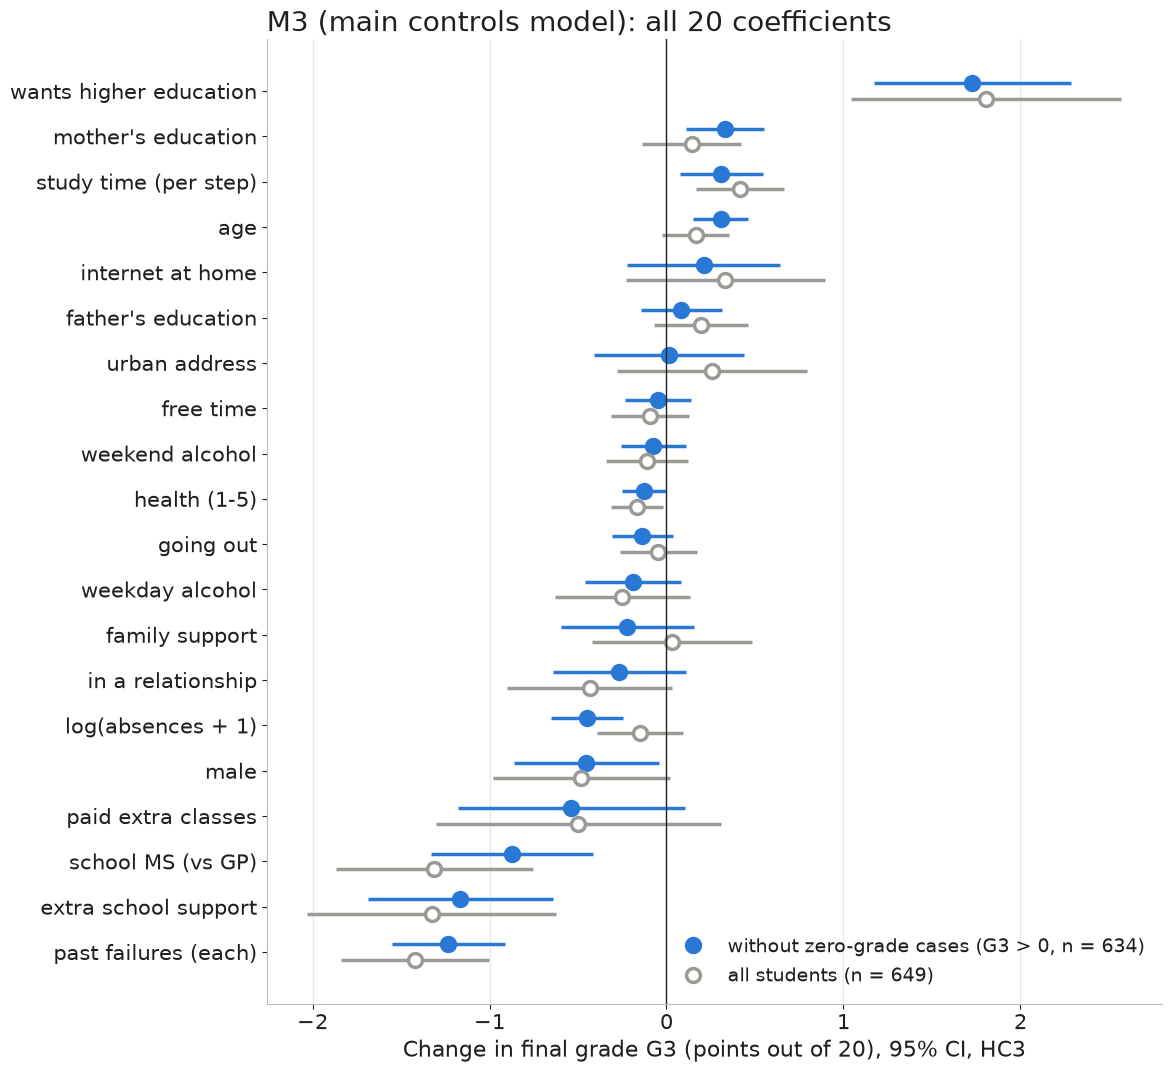

In [6]:
NICE = {"C(higher)[T.yes]": "wants higher education", "failures": "past failures (each)",
        "C(schoolsup)[T.yes]": "extra school support", "C(school)[T.MS]": "school MS (vs GP)",
        "C(sex)[T.M]": "male", "log_abs": "log(absences + 1)", "studytime": "study time (per step)",
        "Medu": "mother's education", "Fedu": "father's education", "age": "age", "health": "health (1-5)",
        "C(famsup)[T.yes]": "family support", "C(paid)[T.yes]": "paid extra classes",
        "C(romantic)[T.yes]": "in a relationship", "C(internet)[T.yes]": "internet at home",
        "C(address)[T.U]": "urban address", "Dalc": "weekday alcohol", "Walc": "weekend alcohol",
        "goout": "going out", "freetime": "free time"}
full = rc[rc.section == "M3 full coefficients"].copy()
full["label"] = full.term.map(NICE)
assert full.label.notna().all()
order = full[full["sample"] == "G3>0"].sort_values("estimate").label.tolist()


def coef_plot(ax, labels, fontsize=15):
    y = {lab: i for i, lab in enumerate(labels)}
    for s, off, c, filled in [("G3>0", 0.17, BLUE, True), ("all", -0.17, GREY, False)]:
        d = full[(full["sample"] == s) & full.label.isin(labels)]
        yy = d.label.map(y) + off
        ax.hlines(yy, d.ci_lo, d.ci_hi, color=c, lw=2.5)
        ax.plot(d.estimate, yy, "o", ms=10, color=c if filled else "white", mec=c, mew=2.5,
                label=("without zero-grade cases (G3 > 0, n = 634)" if s == "G3>0" else "all students (n = 649)"))
    ax.axvline(0, color=INK, lw=1)
    ax.set_yticks(range(len(labels)), labels, fontsize=fontsize)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Change in final grade G3 (points out of 20), 95% CI, HC3")


fig, ax = plt.subplots(figsize=(12, 11))
coef_plot(ax, order)
ax.set_title("M3 (main controls model): all 20 coefficients", loc="left")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout(); plt.show()

**Reading:** wanting higher education (+1.73 on G3 > 0, +1.81 on all) and past failures (-1.23 / -1.42 each) are the
largest adjusted associations. Extra school support is negative (-1.16 / -1.33), almost certainly selection (weak
students are given support), not harm. School MS is negative; family support is not significant. Log absences
are clearly negative only without the zero-grade cases (-0.45 vs -0.15 n.s.).

## 5. The Perfect Attendance Paradox (notebook 04)

In [7]:
z, zm = df[df.zero_grade], mat[mat.zero_grade]
fisher_mat_txt = nb_output("04_zero_grades_and_absences.ipynb", "Fisher (school x zero-grade), maths")
FISHER_MAT_P = float(re.search(r"pvalue=(?:np\.float64\()?([\d.e+-]+)", fisher_mat_txt).group(1))
paradox = pd.DataFrame({
    "Portuguese (main)": {"students": len(df), "zero-grade cases (G3 = 0)": len(z),
                          "...with 0 absences": int((z.absences == 0).sum()),
                          "% zero absences, all students": round(100 * (df.absences == 0).mean(), 1),
                          "zero-grade cases at GP / MS": f"{(z.school == 'GP').sum()} / {(z.school == 'MS').sum()}",
                          "school sizes GP / MS": f"{(df.school == 'GP').sum()} / {(df.school == 'MS').sum()}",
                          "Fisher school x zero-grade p": f"{H('Fisher exact zero-grade x school'):.1e}",
                          "zero-grade mean G1 / G2": f"{z.G1.mean():.2f} / {z.G2.mean():.2f}"},
    "Maths (replication)": {"students": len(mat), "zero-grade cases (G3 = 0)": len(zm),
                            "...with 0 absences": int((zm.absences == 0).sum()),
                            "% zero absences, all students": round(100 * (mat.absences == 0).mean(), 1),
                            "zero-grade cases at GP / MS": f"{(zm.school == 'GP').sum()} / {(zm.school == 'MS').sum()}",
                            "school sizes GP / MS": f"{(mat.school == 'GP').sum()} / {(mat.school == 'MS').sum()}",
                            "Fisher school x zero-grade p": f"{FISHER_MAT_P:.2f}",
                            "zero-grade mean G1 / G2": f"{zm.G1.mean():.2f} / {zm.G2.mean():.2f}"}})
display(paradox)

cols = {"r_abs_G3": "Pearson r(absences, G3)", "M3_logabs": "log(abs+1) in M3", "M3_logabs_p": "p",
        "M4_logabs": "log(abs+1) in M4 (+G1, G2)", "M4_logabs_p": "p ", "M3_BP_p": "Breusch-Pagan p, M3",
        "M4_BP_p": "Breusch-Pagan p, M4"}
before_after = ba[list(cols)].rename(columns=cols)
display(before_after.style.format("{:.3g}"))
display(rb.style.format("{:.3g}"))

,Portuguese (main),Maths (replication)
students,649,395
zero-grade cases (G3 = 0),15,38
...with 0 absences,15,38
"% zero absences, all students",37.6,29.1
zero-grade cases at GP / MS,1 / 14,34 / 4
school sizes GP / MS,423 / 226,349 / 46
Fisher school x zero-grade p,3.0e-06,1.00
zero-grade mean G1 / G2,7.07 / 3.80,7.53 / 4.66


,"Pearson r(absences, G3)",log(abs+1) in M3,p,"log(abs+1) in M4 (+G1, G2)",p,"Breusch-Pagan p, M3","Breusch-Pagan p, M4"
sample,,,,,,,
"Portuguese, all",-0.0914,-0.149,0.232,0.159,0.0227,3.51e-10,0.000118
"Portuguese, G3 > 0",-0.196,-0.448,1.96e-05,-0.00768,0.881,0.236,0.0118
"Maths, all",0.0342,0.985,7.42e-05,0.635,4.96e-07,1.5e-05,4.5e-10
"Maths, G3 > 0",-0.213,-0.549,0.00129,-0.052,0.304,0.144,0.00647


,n,M3_log_abs,M3_log_abs_p,M3_studytime,M3_studytime_p,M4_log_abs,M4_log_abs_p,M4_studytime,M4_studytime_p
treatment,,,,,,,,,
keep zero-grade cases as-is,649,-0.149,0.231,0.415,0.00104,0.159,0.0224,0.0534,0.307
(a) drop zero-grade cases (G3 > 0),634,-0.448,1.69e-05,0.31,0.00878,-0.00768,0.881,0.0143,0.747
(b) zero-grade dummy,649,-0.465,7.62e-06,0.315,0.00788,-0.0254,0.626,0.0267,0.558
(c) restrict to G2 > 0,642,-0.28,0.0187,0.396,0.00144,0.146,0.0512,0.0549,0.289


**Reading:** the fingerprint is **zero recorded absences**: every zero-grade case in both files has 0 absences,
far above the base rate. The **school pattern does not replicate**: in Portuguese 14 of 15 are at MS, but in maths 34
of 38 are at GP, in proportion to school size (Fisher p = 1.0). So the headline is the zero absences, not the school.
With the zero-grade cases included, absences look harmless (M3: -0.15, n.s.) or even helpful (M4: +0.16, p = 0.02;
maths M3: +0.98); without them the log-absence effect is clearly negative (Portuguese M3 -0.45, maths M3 -0.55).
Breusch-Pagan on M3 goes from p = 3.5e-10 to 0.24 once they are removed, **but M4 still fails (p = 0.012)**, so the
heteroskedasticity disappears in the controls model only. Robustness: a zero-grade dummy gives the same M3 answer
as dropping them (-0.47 vs -0.45).

## 6. Diagnostics scorecard (notebook 05)

In [8]:
LIGHT = {"green": "#d7f2e5", "amber": "#fdebc8", "red": "#fbd5d2", "n/a": "#ececea"}
card = sc.copy()
card["statistic"] = card.statistic.map(lambda v: f"{v:.3g}")
card["p_value"] = card.p_value.map(lambda v: "" if pd.isna(v) else f"{v:.2g}")
card["light"] = card.light.fillna("n/a").str.upper()  # "n/a" is read as NaN by pandas
card["light"] = card.light.str.replace("N/A", "N/A (not applicable)")
card = card[["check", "sample", "statistic", "p_value", "light", "action", "detail"]]
(card.style.hide(axis="index")
     .apply(lambda r: [f"background-color: {LIGHT.get(r.light.split(' ')[0].lower(), '#fff')}"] * len(r), axis=1)
     .set_properties(**{"text-align": "left", "font-size": "12px"}))

check,sample,statistic,p_value,light,action,detail
Multicollinearity (max VIF),G3 > 0,1.99,,GREEN,no action,"max = Walc; Medu 1.92, Fedu 1.78, Dalc 1.74, Walc 1.99"
Multicollinearity (max VIF),all,1.97,,GREEN,no action,"max = Walc; Medu 1.91, Fedu 1.78, Dalc 1.71, Walc 1.97"
"Heteroskedasticity, Breusch-Pagan (M3)",G3 > 0,24.2,0.24,GREEN,none needed; HC3 used anyway,LM test on OLS residuals
"Heteroskedasticity, White (M3)",G3 > 0,258,0.045,AMBER,HC3 robust SEs,"special form (yhat, yhat^2): LM 4.4, p 0.112"
"Heteroskedasticity, Breusch-Pagan (M3)",all,86.1,3.5e-10,RED,HC3 robust SEs,LM test on OLS residuals
"Heteroskedasticity, White (M3)",all,347,1.2e-07,RED,HC3 robust SEs,"special form (yhat, yhat^2): LM 11.2, p 0.00371"
"Heteroskedasticity, Breusch-Pagan (M4)",G3 > 0,39.7,0.012,AMBER,HC3 robust SEs,LM test on OLS residuals
"Heteroskedasticity, White (M4)",G3 > 0,386,2.1e-06,RED,HC3 robust SEs,"special form (yhat, yhat^2): LM 2.7, p 0.253"
"Heteroskedasticity, Breusch-Pagan (M4)",all,55,0.00012,RED,HC3 robust SEs,LM test on OLS residuals
"Heteroskedasticity, White (M4)",all,399,2.2e-07,RED,HC3 robust SEs,"special form (yhat, yhat^2): LM 22.2, p 1.48e-05"


Traffic lights carry a text label (GREEN / AMBER / RED / N/A), so the colour is never the only cue.

| Check (M3, G3 > 0; full sample in brackets) | Light | One-liner for slide 7 |
|---|---|---|
| Multicollinearity | green | max VIF 1.99 (Walc) |
| Heteroskedasticity, M3 | green (BP) / amber (full White) [red] | BP p = 0.24 without zero-grade cases, 3.5e-10 with; HC3 used throughout |
| Heteroskedasticity, M4 | amber (BP p = 0.012) [red] | does **not** go away in the G1/G2 model |
| Residual normality | green [amber] | JB p = 0.054; the full-sample left tail is the zero-grade cases |
| Influence | green | max Cook's D 0.037, none > 1 |
| Functional form (RESET) | amber | p = 3e-5; likely the bounded 0-20 scale; reported openly |
| Autocorrelation | n/a | cross-section; DW depends on arbitrary row order |

## 7. Student A vs Student B (notebook 03, the audience-vote twist)

In [9]:
ab_txt = nb_output("03_regression_models.ipynb", "same profiles but both without school support")
EQ = dict(re.findall(r"(all|G3>0)\s+A - B = [+-][\d.]+.*\n\s+same profiles but both without school support: "
                     r"A - B = ([+-][\d.]+)", ab_txt))
EQ = {k: float(v) for k, v in EQ.items()}
assert len(EQ) == 2, ab_txt
prof = rc[rc.section == "profile prediction"][["model", "sample", "term", "estimate", "ci_lo", "ci_hi", "pi_lo", "pi_hi"]]
display(prof.round(2).set_index(["sample", "model", "term"]))
print("M3 gap A - B with school support held equal:", EQ)
print("M3 school-support coefficient (all):", round(R("M3 full coefficients", "M3", "all", "C(schoolsup)[T.yes]"), 2))

estimate  ci_lo  ci_hi  pi_lo  pi_hi
sample model                     term                                           
all    M3 + family/social        Student A     12.60  11.52  13.68   7.25  17.95
                                 Student B     12.22  11.42  13.03   6.92  17.52
       M2 + academic/demographic Student A     12.17  11.13  13.20   6.68  17.65
                                 Student B     13.33  12.97  13.69   7.94  18.73
G3>0   M3 + family/social        Student A     11.97  11.00  12.94   7.60  16.35
                                 Student B     12.15  11.57  12.72   7.84  16.45
       M2 + academic/demographic Student A     11.76  10.80  12.72   7.21  16.30
                                 Student B     13.34  13.03  13.66   8.89  17.80

M3 gap A - B with school support held equal: {'all': -0.93, 'G3>0': -1.34}
M3 school-support coefficient (all): -1.33


**Profiles:** A studies >10 h, 12 absences, 1 past failure, no extra school support; B studies 2-5 h, 2 absences,
no failures, gets school support; everything else at typical values. **M3 predicts A 12.6 and B 12.2** (all students):
the hard-working student with a failure comes out slightly *ahead*. That is driven by the school-support dummy
(-1.33: supported students score lower, a selection effect). **Hold support equal and B leads by 0.93.** Either way the
95% prediction intervals run from about 7 to 18, so the model cannot separate two individuals. Slide use: ask the
audience to vote A or B, reveal 12.6 vs 12.2, then explain the selection effect and the interval width.

## 8. Slide figures (saved to `presentation/`)

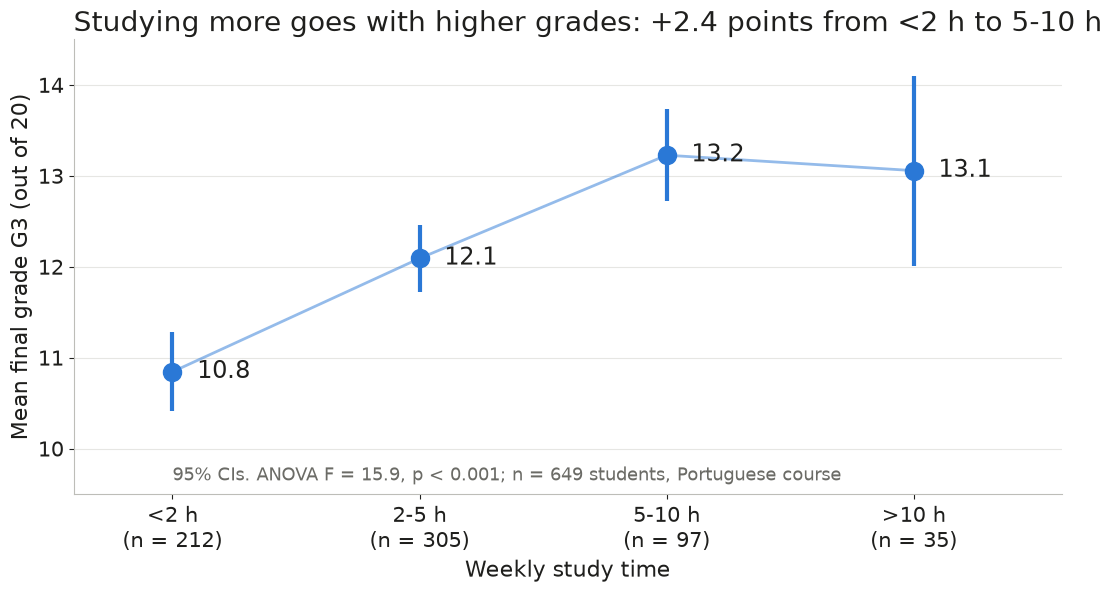

In [10]:
# Figure 1: the study-time gradient (descriptive means with 95% CI), all students
g = grp[grp["sample"] == "all"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 6.2))
x = np.arange(len(g))
ax.errorbar(x, g["mean G3"], yerr=[g["mean G3"] - g.ci_lo, g.ci_hi - g["mean G3"]], fmt="o", color=BLUE,
            ms=13, lw=3, capsize=0)
ax.plot(x, g["mean G3"], color=BLUE, lw=2, alpha=0.5)
for i, r in g.iterrows():
    ax.text(i + 0.1, r["mean G3"], f"{r['mean G3']:.1f}", va="center", ha="left", fontsize=17, color=INK)
ax.set_xticks(x, [f"{s}\n(n = {n})" for s, n in zip(g["study time"], g.n)])
ax.set(ylabel="Mean final grade G3 (out of 20)", ylim=(9.5, 14.5), xlim=(-0.4, 3.6))
ax.set_xlabel("Weekly study time")
tk = ht[(ht.test == "Tukey HSD <2 h vs 5-10 h") & (ht["sample"] == "all")].iloc[0]
ax.set_title(f"Studying more goes with higher grades: +{tk.effect:.1f} points from <2 h to 5-10 h", loc="left")
ax.text(0, 9.65, f"95% CIs. ANOVA F = {H('One-way ANOVA G3 ~ studytime', col='value'):.1f}, p < 0.001; "
        f"n = {len(df)} students, Portuguese course", fontsize=13, color=MUTED)
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(PRES / "fig1_study_time_gradient.png", bbox_inches="tight"); plt.show()

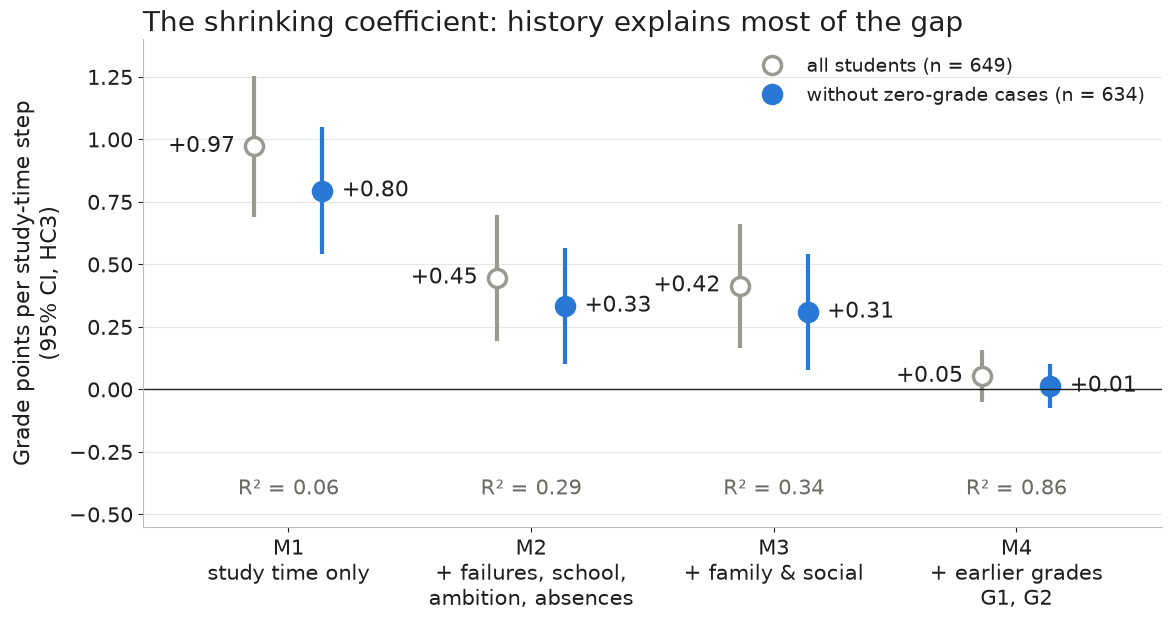

In [11]:
# Figure 2: the shrinking coefficient (M1-M4, both samples)
lad = rc[(rc.section == "ladder (numeric studytime)") & (rc.term == "studytime")].copy()
lad["M"] = lad.model.str[:2]
fig, ax = plt.subplots(figsize=(12, 6.5))
for s, off, c, filled, lab in [("all", -0.14, GREY, False, "all students (n = 649)"),
                               ("G3>0", 0.14, BLUE, True, "without zero-grade cases (n = 634)")]:
    d = lad[lad["sample"] == s].sort_values("M")
    xx = np.arange(4) + off
    ax.vlines(xx, d.ci_lo, d.ci_hi, color=c, lw=3)
    ax.plot(xx, d.estimate, "o", ms=13, color=c if filled else "white", mec=c, mew=2.5, label=lab)
    for xi, (_, r) in zip(xx, d.iterrows()):
        left = s == "all"
        ax.text(xi + (-0.08 if left else 0.08), r.estimate, f"{r.estimate:+.2f}", ha="right" if left else "left",
                va="center", fontsize=16, color=INK)
        if left:
            ax.text(xi + 0.14, -0.42, f"R² = {r.r2:.2f}", ha="center", fontsize=15, color=MUTED)
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(range(4), ["M1\nstudy time only", "M2\n+ failures, school,\nambition, absences",
                         "M3\n+ family & social", "M4\n+ earlier grades\nG1, G2"])
ax.set(ylabel="Grade points per study-time step\n(95% CI, HC3)", ylim=(-0.55, 1.4), xlim=(-0.6, 3.6))
ax.set_title("The shrinking coefficient: history explains most of the gap", loc="left")
ax.legend(loc="upper right", frameon=False)
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(PRES / "fig2_coefficient_ladder.png", bbox_inches="tight"); plt.show()

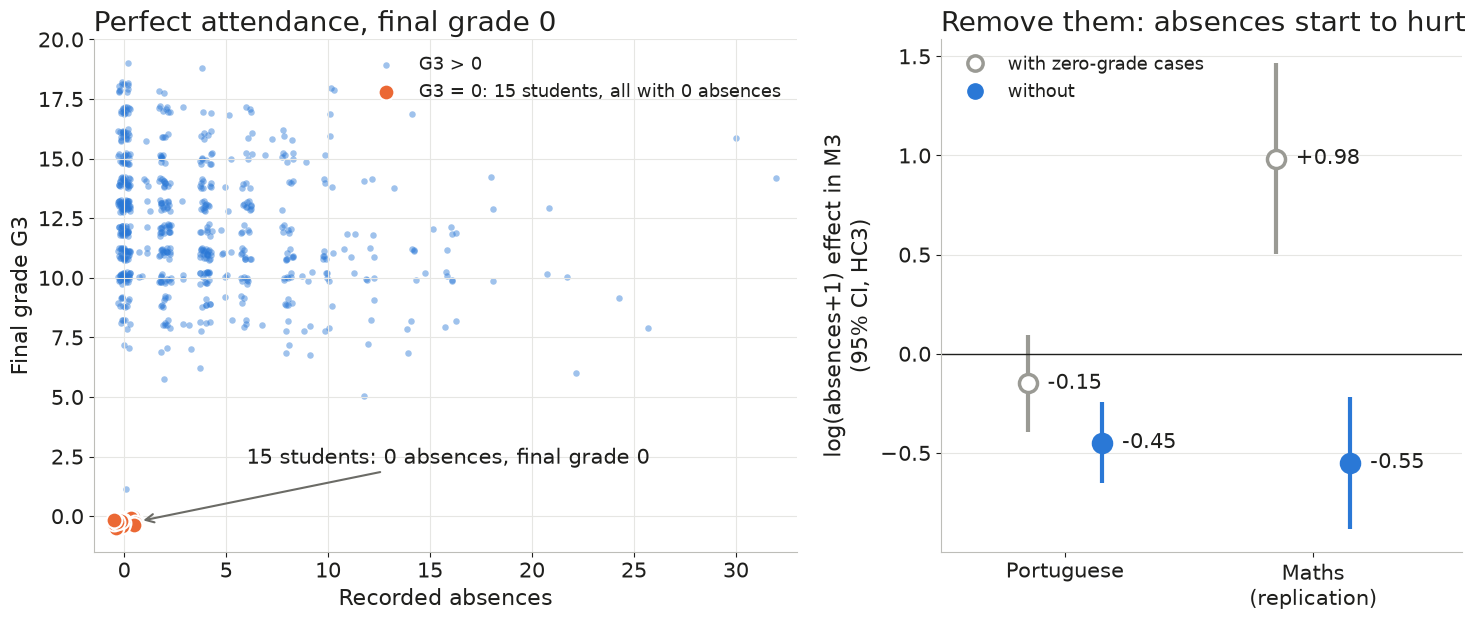

In [12]:
# Figure 3: The Perfect Attendance Paradox
rng = np.random.default_rng(1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]
jx, jy = rng.uniform(-0.3, 0.3, len(df)), rng.uniform(-0.25, 0.25, len(df))
o = ~df.zero_grade.values
ax.scatter(df.absences[o] + jx[o], df.G3[o] + jy[o], s=22, alpha=0.45, color=BLUE, label="G3 > 0", lw=0)
zx = rng.uniform(-0.6, 0.6, (~o).sum()); zy = rng.uniform(-0.6, 0.0, (~o).sum())
ax.scatter(df.absences[~o] + zx, df.G3[~o] + zy, s=130, color=ORANGE, edgecolor="white", lw=1.5, zorder=3,
           label=f"G3 = 0: {int((~o).sum())} students, all with 0 absences")
ax.annotate(f"{int((~o).sum())} students: 0 absences, final grade 0", (0.8, -0.2), xytext=(6, 2.2), fontsize=15,
            color=INK, arrowprops=dict(arrowstyle="->", color=MUTED, lw=1.5))
ax.set(xlabel="Recorded absences", ylabel="Final grade G3", xlim=(-1.5, 33), ylim=(-1.5, 20))
ax.set_title("Perfect attendance, final grade 0", loc="left")
ax.legend(loc="upper right", frameon=False, fontsize=13)
ax = axes[1]
items = [("Portuguese, all", "Portuguese, G3 > 0", "Portuguese"), ("Maths, all", "Maths, G3 > 0", "Maths\n(replication)")]
for i, (a, b, lab) in enumerate(items):
    for s, off, c, filled in [(a, -0.15, GREY, False), (b, 0.15, BLUE, True)]:
        r = ba.loc[s]
        ax.vlines(i + off, r.M3_logabs_lo, r.M3_logabs_hi, color=c, lw=3)
        ax.plot(i + off, r.M3_logabs, "o", ms=13, color=c if filled else "white", mec=c, mew=2.5)
        ax.text(i + off + 0.08, r.M3_logabs, f"{r.M3_logabs:+.2f}", va="center", fontsize=15)
ax.plot([], [], "o", ms=11, color="white", mec=GREY, mew=2.5, label="with zero-grade cases")
ax.plot([], [], "o", ms=11, color=BLUE, label="without")
ax.axhline(0, color=INK, lw=1)
ax.set_xticks([0, 1], [it[2] for it in items])
ax.set(xlim=(-0.5, 1.6), ylabel="log(absences+1) effect in M3\n(95% CI, HC3)")
ax.set_title("Remove them: absences start to hurt", loc="left")
ax.legend(loc="upper left", frameon=False, fontsize=13)
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(PRES / "fig3_perfect_attendance_paradox.png", bbox_inches="tight"); plt.show()

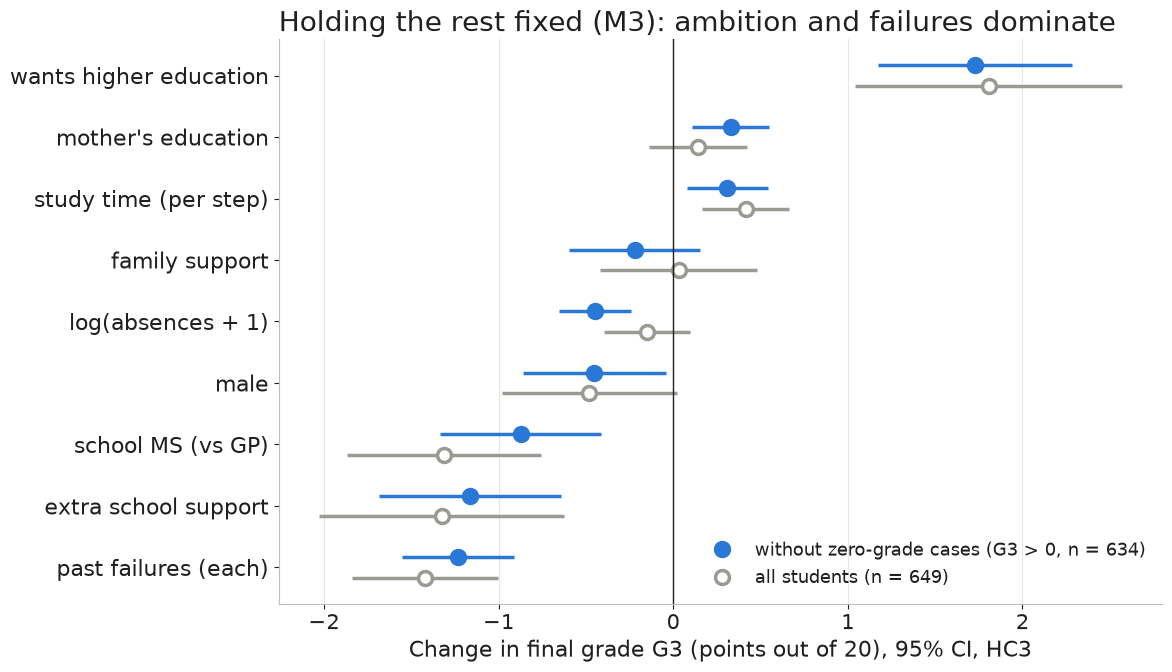

['fig1_study_time_gradient.png', 'fig2_coefficient_ladder.png', 'fig3_perfect_attendance_paradox.png', 'fig4_what_predicts_grades.png']


In [13]:
# Figure 4: what predicts the grade, M3 selected terms (full plot in section 4)
SEL = ["wants higher education", "study time (per step)", "mother's education", "family support",
       "log(absences + 1)", "male", "school MS (vs GP)", "extra school support", "past failures (each)"]
sel = [l for l in order if l in SEL]
fig, ax = plt.subplots(figsize=(12, 7))
coef_plot(ax, sel, fontsize=16)
ax.set_title("Holding the rest fixed (M3): ambition and failures dominate", loc="left")
ax.legend(loc="lower right", frameon=False, fontsize=13)
fig.tight_layout(); fig.savefig(PRES / "fig4_what_predicts_grades.png", bbox_inches="tight"); plt.show()
print(sorted(p.name for p in PRES.glob("*.png")))

## 9. Numbers to quote on slides (each with its source)

In [14]:
def row(slide, what, value, source):
    return {"slide": slide, "what": what, "value": value, "source": source}

g_all = grp[grp["sample"] == "all"].set_index("study time")
r_ = lambda M, s="all", t="studytime", c="estimate": R("ladder (numeric studytime)", M, s, t, c)
Q = [
    row(2, "students (Portuguese course) / zero-grade cases", f"{len(df)} / {int(df.zero_grade.sum())}", "00, 01"),
    row(3, "mean G3 by study time <2 / 2-5 / 5-10 / >10 h",
        " / ".join(f"{g_all.loc[k, 'mean G3']:.2f}" for k in ST_LABELS.values()), "01, 02 (06 sec. 1)"),
    row(3, "Tukey <2 h vs 5-10 h", f"+{H('Tukey HSD <2 h vs 5-10 h', col='effect'):.2f} "
        + ci(H('Tukey HSD <2 h vs 5-10 h', col='effect_ci_lo'), H('Tukey HSD <2 h vs 5-10 h', col='effect_ci_hi')), "02"),
    row(3, "ANOVA F, p, eta²", f"F(3, 645) = {H('One-way ANOVA G3 ~ studytime', col='value'):.2f}, "
        f"p = {H('One-way ANOVA G3 ~ studytime'):.1e}, eta² = {H('One-way ANOVA G3 ~ studytime', col='effect'):.3f}", "02"),
    row(3, "Levene p / Kruskal-Wallis p", f"{H('Levene equal variances (G3 by studytime)'):.2f} / "
        f"{H('Kruskal-Wallis G3 ~ studytime'):.1e}", "02"),
    row(3, "MANOVA Pillai, p", f"{H('MANOVA (G1,G2,G3) ~ studytime', col='effect'):.3f}, "
        f"p = {H('MANOVA (G1,G2,G3) ~ studytime'):.1e}", "02"),
    row(4, "study time b, M1 -> M2 -> M3 -> M4 (all)", " -> ".join(f"{r_(M):+.2f}" for M in ["M1", "M2", "M3", "M4"]), "03"),
    row(4, "R², M1 -> M4 (all)", " -> ".join(f"{r_(M, c='r2'):.2f}" for M in ["M1", "M2", "M3", "M4"]), "03"),
    row(4, "study time b, M1 -> M4 (G3 > 0)", " -> ".join(f"{r_(M, 'G3>0'):+.2f}" for M in ["M1", "M2", "M3", "M4"]), "03"),
    row(4, "M3 study time p, G3 > 0: linear / dummies joint", f"{r_('M3', 'G3>0', c='p_value'):.3f} / {JOINT[('M3', 'G3>0')]:.3f}", "03"),
    row(4, "ANCOVA (G1 covariate): study time p, partial eta²",
        f"{H('ANCOVA G3 ~ C(studytime) + G1: studytime'):.3f}, {H('ANCOVA G3 ~ C(studytime) + G1: studytime', col='effect'):.3f}", "02"),
    row(5, "wants higher education: raw gap, Cohen's d",
        H('Welch t G3 by higher (yes - no)', col='note').replace('mean diff ', '')
        + f", d = {H('Welch t G3 by higher (yes - no)', col='effect'):.2f}", "02"),
    row(5, "wants higher education in M3 (all / G3 > 0)",
        f"{R('M3 full coefficients', 'M3', 'all', 'C(higher)[T.yes]'):+.2f} / {R('M3 full coefficients', 'M3', 'G3>0', 'C(higher)[T.yes]'):+.2f}", "03"),
    row(5, "past failures in M3 (all / G3 > 0)",
        f"{R('M3 full coefficients', 'M3', 'all', 'failures'):+.2f} / {R('M3 full coefficients', 'M3', 'G3>0', 'failures'):+.2f}", "03"),
    row(5, "family support: raw gap, p", ht[(ht.test == 'Welch t G3 by famsup (yes - no)') & (ht['sample'] == 'all')].note.iloc[0]
        + f", p = {H('Welch t G3 by famsup (yes - no)'):.2f}", "02"),
    row(5, "extra school support in M3 (all)", f"{R('M3 full coefficients', 'M3', 'all', 'C(schoolsup)[T.yes]'):+.2f} (selection)", "03"),
    row(6, "zero-grade cases with 0 absences (Portuguese / maths)",
        f"{int((z.absences == 0).sum())} of {len(z)} / {int((zm.absences == 0).sum())} of {len(zm)}", "04"),
    row(6, "share of all students with 0 absences (Portuguese / maths)",
        f"{100 * (df.absences == 0).mean():.1f}% / {100 * (mat.absences == 0).mean():.1f}%", "04"),
    row(6, "log(abs+1) in M3: with -> without zero-grade cases (Portuguese)",
        f"{ba.loc['Portuguese, all', 'M3_logabs']:+.2f} (p = {ba.loc['Portuguese, all', 'M3_logabs_p']:.2f}) -> "
        f"{ba.loc['Portuguese, G3 > 0', 'M3_logabs']:+.2f} (p = {ba.loc['Portuguese, G3 > 0', 'M3_logabs_p']:.0e})", "04"),
    row(6, "log(abs+1) in M4 with zero-grade cases (Portuguese)",
        f"{ba.loc['Portuguese, all', 'M4_logabs']:+.2f} (p = {ba.loc['Portuguese, all', 'M4_logabs_p']:.3f})", "04"),
    row(6, "Breusch-Pagan p on M3: with -> without", f"{ba.loc['Portuguese, all', 'M3_BP_p']:.1e} -> {ba.loc['Portuguese, G3 > 0', 'M3_BP_p']:.2f}", "04, 05"),
    row(7, "Breusch-Pagan p on M4 without zero-grade cases", f"{ba.loc['Portuguese, G3 > 0', 'M4_BP_p']:.3f}", "04, 05"),
    row(7, "max VIF (M3, G3 > 0)", f"{S('Multicollinearity (max VIF)', 'G3 > 0'):.2f}", "05"),
    row(7, "RESET power 2, M3 log(abs+1), G3 > 0: F, p",
        f"{S('Functional form, RESET power 2 (M3, log(abs+1))', 'G3 > 0'):.1f}, {S('Functional form, RESET power 2 (M3, log(abs+1))', 'G3 > 0', 'p_value'):.0e}", "05"),
    row(7, "functional form, M3 all students: AIC linear / log / quadratic",
        " / ".join(f"{R('functional form (in M3)', f, 'all', t, 'aic'):.1f}" for f, t in
                   [("linear", "absences"), ("log(abs+1)", "log_abs"), ("quadratic", "absences")]), "03"),
    row(7, "squared absences term p in M3 (all / G3 > 0)",
        f"{R('functional form (in M3)', 'quadratic', 'all', 'I(absences ** 2)', 'p_value'):.2f} / "
        f"{R('functional form (in M3)', 'quadratic', 'G3>0', 'I(absences ** 2)', 'p_value'):.2f}", "03"),
    row(7, "absences skewness (all students)", f"{df.absences.skew():.2f}", "06 (computed from data)"),
    row("twist", "Student A vs B, M3 all (prediction, 95% PI)",
        " vs ".join(f"{R('profile prediction', 'M3', 'all', w):.1f} ({R('profile prediction', 'M3', 'all', w, 'pi_lo'):.1f}-"
                    f"{R('profile prediction', 'M3', 'all', w, 'pi_hi'):.1f})" for w in ["Student A", "Student B"]), "03"),
    row("twist", "A - B with school support held equal (all / G3 > 0)", f"{EQ['all']:+.2f} / {EQ['G3>0']:+.2f}", "03 (printed output)"),
    row("backup", "maths: log(abs+1) in M3 with -> without", f"{ba.loc['Maths, all', 'M3_logabs']:+.2f} -> {ba.loc['Maths, G3 > 0', 'M3_logabs']:+.2f}", "04"),
    row("backup", "maths zero-grade cases at GP (GP share of maths students)",
        f"{(zm.school == 'GP').sum()} of {len(zm)} ({100 * (mat.school == 'GP').mean():.0f}% of students at GP), Fisher p = {FISHER_MAT_P:.2f}", "04"),
    row("backup", "study time x failures (M3 controls): all / G3 > 0",
        f"{R('interaction (full M3 controls)', 'studytime x failures', 'all', 'studytime:failures'):+.2f} (p = "
        f"{R('interaction (full M3 controls)', 'studytime x failures', 'all', 'studytime:failures', 'p_value'):.2f}) / "
        f"{R('interaction (full M3 controls)', 'studytime x failures', 'G3>0', 'studytime:failures'):+.2f} (p = "
        f"{R('interaction (full M3 controls)', 'studytime x failures', 'G3>0', 'studytime:failures', 'p_value'):.3f})", "03"),
    row("backup", "study time x sex interaction p (all / G3 > 0)",
        f"{H('Two-way ANOVA (studytime x sex): C(studytime):C(sex)'):.3f} / {H('Two-way ANOVA (studytime x sex): C(studytime):C(sex)', 'G3>0'):.3f}", "02"),
]
QUOTE = pd.DataFrame(Q)
with pd.option_context("display.max_colwidth", 120):
    display(QUOTE)

,slide,what,value,source
0,2,students (Portuguese course) / zero-grade cases,649 / 15,"00, 01"
1,3,mean G3 by study time <2 / 2-5 / 5-10 / >10 h,10.84 / 12.09 / 13.23 / 13.06,"01, 02 (06 sec. 1)"
2,3,Tukey <2 h vs 5-10 h,"+2.38 [+1.40, +3.37]",02
3,3,"ANOVA F, p, eta²","F(3, 645) = 15.88, p = 5.7e-10, eta² = 0.069",02
4,3,Levene p / Kruskal-Wallis p,0.38 / 6.8e-11,02
5,3,"MANOVA Pillai, p","0.085, p = 9.9e-09",02
6,4,"study time b, M1 -> M2 -> M3 -> M4 (all)",+0.97 -> +0.45 -> +0.42 -> +0.05,03
7,4,"R², M1 -> M4 (all)",0.06 -> 0.29 -> 0.34 -> 0.86,03
8,4,"study time b, M1 -> M4 (G3 > 0)",+0.80 -> +0.33 -> +0.31 -> +0.01,03
9,4,"M3 study time p, G3 > 0: linear / dummies joint",0.009 / 0.063,03


## 10. One-page executive summary
Generated from the tables above and written to `presentation/executive_summary.md`.

In [15]:
q = QUOTE.set_index("what").value
tk_lo, tk_hi = H("Tukey HSD <2 h vs 5-10 h", col="effect_ci_lo"), H("Tukey HSD <2 h vs 5-10 h", col="effect_ci_hi")
summary = f"""# Study Smarter, Not Harder: executive summary
*MPBA G505 group project · working title · data: Cortez (2008), UCI Student Performance, CC BY 4.0*

**Question.** Does studying more pay off in final grades, and does that survive a fair comparison?
**Data.** {len(df)} students in a Portuguese-language course at two schools (G3 = final grade, 0-20); the
maths file ({len(mat)} students) is used as a replication. Models M1-M4 are nested OLS with HC3 robust SEs:
M1 study time only; M2 + academic/demographic; M3 + family/social (main model); M4 + earlier grades G1, G2.

**1. Effort shows up.** Mean G3 rises from {g_all.loc['<2 h', 'mean G3']:.1f} (<2 h/week) to {g_all.loc['5-10 h', 'mean G3']:.1f}
(5-10 h), a gap of {H('Tukey HSD <2 h vs 5-10 h', col='effect'):.2f} points (95% CI {tk_lo:.2f}-{tk_hi:.2f}); ANOVA {q['ANOVA F, p, eta²']}.
Beyond 10 h there is no further gain ({g_all.loc['>10 h', 'mean G3']:.1f}, n = {int(g_all.loc['>10 h', 'n'])}).

**2. History dominates.** The study-time coefficient falls {q['study time b, M1 -> M2 -> M3 -> M4 (all)']} from M1 to M4
while R² rises {q['R², M1 -> M4 (all)']}. Most of the drop comes from failures, school, ambition and absences (M2).
Without the zero-grade cases the M3 linear term is significant (p = {r_('M3', 'G3>0', c='p_value'):.3f}) but the
study-time dummies are only jointly borderline (p = {JOINT[('M3', 'G3>0')]:.3f}).

**3. Ambition beats support.** Wanting higher education is the largest single difference
({q["wants higher education: raw gap, Cohen's d"]}; {R('M3 full coefficients', 'M3', 'all', 'C(higher)[T.yes]'):+.2f} in M3). Each past failure goes with
{R('M3 full coefficients', 'M3', 'all', 'failures'):+.2f} points in M3. Family support shows no difference
({q['family support: raw gap, p']}); extra school support is negative ({R('M3 full coefficients', 'M3', 'all', 'C(schoolsup)[T.yes]'):+.2f}),
which reflects who receives it (selection), not harm.

**4. The Perfect Attendance Paradox.** All {len(z)} students with G3 = 0 have **zero recorded absences**
(vs {100 * (df.absences == 0).mean():.1f}% of all students), and all {len(zm)} in maths do too. We read them as apparent
dropouts; that is our interpretation, the dataset does not say. With them included, absences look harmless
(M3: {ba.loc['Portuguese, all', 'M3_logabs']:+.2f}, p = {ba.loc['Portuguese, all', 'M3_logabs_p']:.2f}) or even helpful
(M4: {ba.loc['Portuguese, all', 'M4_logabs']:+.2f}, p = {ba.loc['Portuguese, all', 'M4_logabs_p']:.2f}); without them the
log-absence effect is {ba.loc['Portuguese, G3 > 0', 'M3_logabs']:+.2f} (p < 0.001). Maths replicates it
({ba.loc['Maths, all', 'M3_logabs']:+.2f} with vs {ba.loc['Maths, G3 > 0', 'M3_logabs']:+.2f} without). The school concentration does
**not** replicate (Portuguese: {(z.school == 'MS').sum()} of {len(z)} at MS; maths: {(zm.school == 'GP').sum()} of {len(zm)} at GP,
in proportion to school size).

**5. Diagnostics.** No multicollinearity (max VIF {S('Multicollinearity (max VIF)', 'G3 > 0'):.2f}). Removing the zero-grade
cases fixes heteroskedasticity in M3 (Breusch-Pagan p {q['Breusch-Pagan p on M3: with -> without']}) but not in M4
(p = {ba.loc['Portuguese, G3 > 0', 'M4_BP_p']:.3f}); HC3 SEs are used throughout. RESET still rejects (p = {S('Functional form, RESET power 2 (M3, log(abs+1))', 'G3 > 0', 'p_value'):.0e}), likely the bounded
0-20 scale. log(absences+1) is used because absences are highly skewed (skewness {df.absences.skew():.1f}); with the zero-grade
cases a linear term fits best by AIC and the squared term is never significant.

**6. A profile predicts the average, not the person.** A (>10 h, 12 absences, 1 failure, no support) vs
B (2-5 h, 2 absences, no failures, school support): M3 predicts {q['Student A vs B, M3 all (prediction, 95% PI)']}.
A edges ahead only because of the school-support selection effect; with support equal, B leads by {-EQ['all']:.2f}.

**Verdict.** Effort shows up, history dominates, and absences matter once you check your zeros.
**Limits.** Observational (study time is self-chosen and probably endogenous; no instrument); G1/G2 are partly outcomes
of studying, so M4 understates effort; two schools, 2005-06; self-reported 4-level study time.
"""
(PRES / "executive_summary.md").write_text(summary)
display(Markdown(summary))
print(len(summary.split()), "words")

# Study Smarter, Not Harder: executive summary
*MPBA G505 group project · working title · data: Cortez (2008), UCI Student Performance, CC BY 4.0*

**Question.** Does studying more pay off in final grades, and does that survive a fair comparison?
**Data.** 649 students in a Portuguese-language course at two schools (G3 = final grade, 0-20); the
maths file (395 students) is used as a replication. Models M1-M4 are nested OLS with HC3 robust SEs:
M1 study time only; M2 + academic/demographic; M3 + family/social (main model); M4 + earlier grades G1, G2.

**1. Effort shows up.** Mean G3 rises from 10.8 (<2 h/week) to 13.2
(5-10 h), a gap of 2.38 points (95% CI 1.40-3.37); ANOVA F(3, 645) = 15.88, p = 5.7e-10, eta² = 0.069.
Beyond 10 h there is no further gain (13.1, n = 35).

**2. History dominates.** The study-time coefficient falls +0.97 -> +0.45 -> +0.42 -> +0.05 from M1 to M4
while R² rises 0.06 -> 0.29 -> 0.34 -> 0.86. Most of the drop comes from failures, school, ambition and absences (M2).
Without the zero-grade cases the M3 linear term is significant (p = 0.009) but the
study-time dummies are only jointly borderline (p = 0.063).

**3. Ambition beats support.** Wanting higher education is the largest single difference
(+3.48 [+2.72, +4.23], d = 1.14; +1.81 in M3). Each past failure goes with
-1.42 points in M3. Family support shows no difference
(mean diff +0.39 [-0.14, +0.93], p = 0.15); extra school support is negative (-1.33),
which reflects who receives it (selection), not harm.

**4. The Perfect Attendance Paradox.** All 15 students with G3 = 0 have **zero recorded absences**
(vs 37.6% of all students), and all 38 in maths do too. We read them as apparent
dropouts; that is our interpretation, the dataset does not say. With them included, absences look harmless
(M3: -0.15, p = 0.23) or even helpful
(M4: +0.16, p = 0.02); without them the
log-absence effect is -0.45 (p < 0.001). Maths replicates it
(+0.98 with vs -0.55 without). The school concentration does
**not** replicate (Portuguese: 14 of 15 at MS; maths: 34 of 38 at GP,
in proportion to school size).

**5. Diagnostics.** No multicollinearity (max VIF 1.99). Removing the zero-grade
cases fixes heteroskedasticity in M3 (Breusch-Pagan p 3.5e-10 -> 0.24) but not in M4
(p = 0.012); HC3 SEs are used throughout. RESET still rejects (p = 3e-05), likely the bounded
0-20 scale. log(absences+1) is used because absences are highly skewed (skewness 2.0); with the zero-grade
cases a linear term fits best by AIC and the squared term is never significant.

**6. A profile predicts the average, not the person.** A (>10 h, 12 absences, 1 failure, no support) vs
B (2-5 h, 2 absences, no failures, school support): M3 predicts 12.6 (7.2-17.9) vs 12.2 (6.9-17.5).
A edges ahead only because of the school-support selection effect; with support equal, B leads by 0.93.

**Verdict.** Effort shows up, history dominates, and absences matter once you check your zeros.
**Limits.** Observational (study time is self-chosen and probably endogenous; no instrument); G1/G2 are partly outcomes
of studying, so M4 understates effort; two schools, 2005-06; self-reported 4-level study time.


527 words


## 11. Limitations and citation
- Observational data: associations, not causes; study time is self-chosen and probably endogenous (simultaneity,
  omitted motivation), and there is no instrument.
- G1/G2 are "bad controls" for effort, so M4 understates the total effect of studying.
- The dropout reading of the zero-grade cases is our interpretation; every key result is shown with and without them.
- Coarse self-reported study time, bounded 0-20 outcome (RESET), two schools in one year, n = 35 in the top group.

Cortez, P. (2008). *Student Performance* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T. CC BY 4.0.